### Load Data

In [266]:
#Load data
import pandas as pd
import numpy as np
import seaborn as sns

liver_data = pd.read_csv('../NCDB_2022/liver.csv')
liver_data.shape

/var/folders/4r/chd7cdjn77j6krd2g7fstr3h0000gn/T/ipykernel_74816/3896725045.py:6: DtypeWarning: Columns (164,170,173,176,177,179,218,219,220,319,320,322,323,331,332,333,334) have mixed types. Specify dtype option on import or set low_memory=False.
  liver_data = pd.read_csv('../NCDB_2022/liver.csv')


(317111, 340)

### Include HCC

In [267]:
#removed 8171 and 8180 per doctor's suggestion
valid_hist_codes = [8170, 8172, 8173, 8174, 8175]

df = liver_data[liver_data['HISTOLOGY'].isin(valid_hist_codes)]
df['HISTOLOGY'].value_counts()

HISTOLOGY
8170    281612
8174      1724
8172       474
8173       256
8175        43
Name: count, dtype: int64

In [268]:
df.shape

(284109, 340)

### Include TACE and Systemic

In [269]:
df = df[
    df['RX_SUMM_CHEMO'].isin([1, 2, 3]) &
    df['DX_CHEMO_STARTED_DAYS'].notna() &
    df['DX_IMMUNO_STARTED_DAYS'].notna()
]

df.shape

(2418, 340)

### Exclude missing survival data

In [270]:
df = df[
    (df['PUF_VITAL_STATUS'].isin([0, 1])) &
    (df['DX_LASTCONTACT_DEATH_MONTHS'].notna()) &
    (df['DX_LASTCONTACT_DEATH_MONTHS'] != 9999.0)
]

df.shape

(2030, 340)

### Define time and event

In [271]:
df['time'] = df['DX_LASTCONTACT_DEATH_MONTHS']
df['event'] = df['PUF_VITAL_STATUS'].apply(lambda x: 1 if x == 0 else 0)  # 1 = dead = event

### Combine stage variables

#### Analytic stage group

In [272]:
df['ANALYTIC_STAGE_GROUP'].value_counts(), df['ANALYTIC_STAGE_GROUP'].isna().sum(), df['ANALYTIC_STAGE_GROUP'].dtype

(ANALYTIC_STAGE_GROUP
 4    752
 3    723
 2    265
 1    181
 9    108
 8      1
 Name: count, dtype: int64,
 np.int64(0),
 dtype('int64'))

In [273]:
df['ANALYTIC_STAGE_GROUP'] = df['ANALYTIC_STAGE_GROUP'].where(df['ANALYTIC_STAGE_GROUP'].isin([1,2,3,4]), np.nan)
df['ANALYTIC_STAGE_GROUP'].value_counts(), df['ANALYTIC_STAGE_GROUP'].isna().sum(), df['ANALYTIC_STAGE_GROUP'].dtype

(ANALYTIC_STAGE_GROUP
 4.0    752
 3.0    723
 2.0    265
 1.0    181
 Name: count, dtype: int64,
 np.int64(109),
 dtype('float64'))

#### Clinical and pathological stage groups

In [274]:
df['COMBINED_CLIN_STAGE_GROUP'] = df['AJCC_TNM_CLIN_STG_GRP'].combine_first(df['TNM_CLIN_STAGE_GROUP'])
df['COMBINED_PATH_STAGE_GROUP'] = df['AJCC_TNM_PATH_STG_GRP'].combine_first(df['TNM_PATH_STAGE_GROUP'])
df['CLIN_PATH_STAGE_GROUP'] = df['COMBINED_CLIN_STAGE_GROUP'].combine_first(df['COMBINED_PATH_STAGE_GROUP'])
df['CLIN_PATH_STAGE_GROUP'].value_counts(), df['CLIN_PATH_STAGE_GROUP'].isna().sum(), df['CLIN_PATH_STAGE_GROUP'].dtype

(CLIN_PATH_STAGE_GROUP
 4B    523
 3A    409
 3B    299
 2     256
 4A    188
 99    120
 1B     99
 1      60
 4      37
 1A     25
 3C     11
 3       1
 88      1
 Name: count, dtype: int64,
 np.int64(1),
 dtype('O'))

In [275]:
stage_map = {
    '1A': 1, '1B': 1, '1':1, 
    '2': 2,
    '3A': 3, '3B': 3, '3C': 3, '3':3,
    '4A': 4, '4B': 4, '4':4
}
df['CLIN_PATH_STAGE_GROUP'] = df['CLIN_PATH_STAGE_GROUP'].astype(str)\
    .replace(stage_map)\
    .where(df['CLIN_PATH_STAGE_GROUP'].isin(stage_map), np.nan)\
    .astype(float)
df['CLIN_PATH_STAGE_GROUP'].value_counts(), df['CLIN_PATH_STAGE_GROUP'].isna().sum()

(CLIN_PATH_STAGE_GROUP
 4.0    748
 3.0    720
 2.0    256
 1.0    184
 Name: count, dtype: int64,
 np.int64(122))

#### TNM

In [276]:
import re

df['COMBINED_N'] = df['TNM_CLIN_N']\
    .combine_first(df['AJCC_TNM_CLIN_N'])\
    .combine_first(df['TNM_PATH_N'])\
    .combine_first(df['AJCC_TNM_PATH_N'])
df['COMBINED_N'].replace('88', np.nan, inplace=True)
df['COMBINED_N'] = df['COMBINED_N'].astype(str).apply(
    lambda x: re.search(r'\d+', x).group() if re.search(r'\d+', x) else np.nan
)

df['COMBINED_T'] = df['TNM_CLIN_T']\
    .combine_first(df['AJCC_TNM_CLIN_T'])\
    .combine_first(df['TNM_PATH_T'])\
    .combine_first(df['AJCC_TNM_PATH_T'])
df['COMBINED_T'].replace('88', np.nan, inplace=True)
df['COMBINED_T'] = df['COMBINED_T'].astype(str).apply(
    lambda x: re.search(r'\d+', x).group() if re.search(r'\d+', x) else np.nan
)


df['COMBINED_M'] = df['TNM_CLIN_M']\
    .combine_first(df['AJCC_TNM_CLIN_M'])\
    .combine_first(df['TNM_PATH_M'])\
    .combine_first(df['AJCC_TNM_PATH_M'])
df['COMBINED_M'].replace('88', np.nan, inplace=True)
df['COMBINED_M'] = df['COMBINED_M'].astype(str).apply(
    lambda x: re.search(r'\d+', x).group() if re.search(r'\d+', x) else np.nan
)

/var/folders/4r/chd7cdjn77j6krd2g7fstr3h0000gn/T/ipykernel_74816/1723192148.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['COMBINED_N'].replace('88', np.nan, inplace=True)
/var/folders/4r/chd7cdjn77j6krd2g7fstr3h0000gn/T/ipykernel_74816/1723192148.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values

#### Final

In [277]:
#Selected for superior completeness
df['COMBINED_STAGE_GROUP'] = df['ANALYTIC_STAGE_GROUP']

### Define sequence label

In [278]:
df['sequence_group'] = df.apply(
    lambda row: 0 if row['DX_CHEMO_STARTED_DAYS'] < row['DX_IMMUNO_STARTED_DAYS']
    else 1,
    axis=1
)

same_day = (df['DX_CHEMO_STARTED_DAYS'] - df['DX_IMMUNO_STARTED_DAYS']).abs() < 1e-6

df.loc[same_day, 'sequence_group'] = 2

df['sequence_group'].value_counts()

sequence_group
0    1313
2     388
1     329
Name: count, dtype: int64

### Recode other covariates

In [279]:
covariates = [
    'AGE', 'SEX', 'RACE', 'SPANISH_HISPANIC_ORIGIN', #Demographics
    'INSURANCE_STATUS', 'MED_INC_QUAR_2020', 'NO_HSD_QUAR_2020',#Socioeconomic
    'CDCC_TOTAL_BEST', 'HISTOLOGY', 'TUMOR_SIZE_SUMMARY_2016', 'COMBINED_STAGE_GROUP', 'COMBINED_T', 'COMBINED_N', 'COMBINED_M',
    'FACILITY_TYPE_CD', 'FACILITY_LOCATION_CD', #Facility
    'YEAR_OF_DIAGNOSIS' #Temporal
]


#Recode year of diagnosis
def collapse_year(year):
    if year >= 2020:
        return '2020+'
    elif year >= 2018:
        return '2018–2019'
    else:
        return '≤2017'

df['YEAR_OF_DIAGNOSIS'] = df['YEAR_OF_DIAGNOSIS'].apply(collapse_year)


# Recode SEX
df['SEX'] = df['SEX'].replace({1: 'Male', 2: 'Female'})

# Recode RACE
df['RACE'] = df['RACE'].astype(str).map({
    '01': 'White',
    '02': 'Black',
    '04': 'Asian', '05': 'Asian', '06': 'Asian', '08': 'Asian', '10': 'Asian',
    '11': 'Asian', '12': 'Asian', '13': 'Asian', '14': 'Asian', '15': 'Asian',
    '16': 'Asian', '17': 'Asian', '96': 'Asian',
    '03': 'Pacific Islander', '20': 'Pacific Islander', '21': 'Pacific Islander',
    '22': 'Pacific Islander', '25': 'Pacific Islander', '26': 'Pacific Islander',
    '27': 'Pacific Islander', '28': 'Pacific Islander', '30': 'Pacific Islander',
    '31': 'Pacific Islander', '32': 'Pacific Islander', '97': 'Pacific Islander'
}).fillna('Other')

# Recode INSURANCE_STATUS
df['INSURANCE_STATUS'] = df['INSURANCE_STATUS'].map({
    0: 'No insurance',
    1: 'Private/Managed Care',
    2: 'Medicaid',
    3: 'Medicare',
    4: 'Other Government',
    9: np.nan
})

# Recode area_MedianIncome2016_2020 from MED_INC_QUAR_2020
df['MEDIAN_INCOME'] = df['MED_INC_QUAR_2020'].map({
    1: '<$46,277',
    2: '$46,277-$57,856',
    3: '$57,857-$74,062',
    4: '>$74,063'
})

# Recode Charlson-Deyo Score
df['Charlson_Deyo_Score'] = df['CDCC_TOTAL_BEST'].map({
    0: '0',
    1: '1',
    2: '2',
    3: '3'
})

# Recode area_NoHighSchooldegree2016_2020
df['NoHighSchooldegree2016_2020'] = df['NO_HSD_QUAR_2020'].map({
    1: '>=15.3%',
    2: '9.1%-15.2%',
    3: '5.0%-9.0%',
    4: '<5.0%'
})

# Recode facility type
df['FACILITY_TYPE'] = df['FACILITY_TYPE_CD'].map({
    1: 'Community Cancer Program',
    2: 'Comprehensive Community Cancer Program',
    3: 'Academic/Research Program',
    4: 'Integrated Network Cancer Program'
})

# Recode HISTOLOGY for HCC
hcc_hist_map = {
    8170: 'HCC, NOS',
    8171: 'Fibrolamellar HCC',
    8172: 'Scirrhous HCC',
    8173: 'Spindle cell HCC',
    8174: 'Clear cell HCC',
    8175: 'Pleomorphic HCC',
    8180: 'Mixed HCC-Cholangiocarcinoma'
}
df['HISTOLOGY'] = df['HISTOLOGY'].map(hcc_hist_map).fillna('Unknown')

# Recode the region values using map()
region_map = {
    1: "New England",
    2: "Middle Atlantic",
    3: "South Atlantic",
    4: "East North Central",
    5: "East South Central",
    6: "West North Central",
    7: "West South Central",
    8: "Mountain",
    9: "Pacific"
}

df['FACILITY_REGION'] = df['FACILITY_LOCATION_CD'].map(region_map)

#Recode hispanic origin
def recode_hispanic_origin(x):
    if x == 0:
        return "Non-Hispanic"
    elif x in [1, 2, 3, 4, 5, 6, 8]:
        return "Hispanic"
    elif x == 7:
        return "Likely Hispanic"
    else:
        return np.nan

df['HISPANIC'] = df['SPANISH_HISPANIC_ORIGIN'].apply(recode_hispanic_origin)

# Recode tumor size
df['TUMOR_SIZE_SUMMARY_2016'] = pd.to_numeric(df['TUMOR_SIZE_SUMMARY_2016'], errors='coerce')
df.loc[df['TUMOR_SIZE_SUMMARY_2016'] > 300, 'TUMOR_SIZE_SUMMARY_2016'] = np.nan

def bin_tumor_size(x):
    if pd.isna(x):
        return np.nan
    elif x == 0:
        return 'No tumor'
    elif x <= 30:
        return '≤3 cm'
    elif x <= 50:
        return '3–5 cm'
    elif x <= 100:
        return '5–10 cm'
    elif x <= 200:
        return '10–20 cm'
    else:
        return '>20 cm'
    
df['TUMOR_SIZE'] = df['TUMOR_SIZE_SUMMARY_2016'].apply(bin_tumor_size)

In [280]:
#Updated covariates list with new names
covariates = [
    'AGE', 'SEX', 'RACE', 'HISPANIC', #Demographics
    'INSURANCE_STATUS', 'MEDIAN_INCOME', 'NoHighSchooldegree2016_2020',#Socioeconomic
    'Charlson_Deyo_Score', 'HISTOLOGY', 'TUMOR_SIZE', 'COMBINED_STAGE_GROUP', 'COMBINED_T', 'COMBINED_N', 'COMBINED_M',
    'FACILITY_TYPE', 'FACILITY_REGION', #Facility
    'YEAR_OF_DIAGNOSIS' #Temporal
]

In [281]:
df[covariates].isna().sum()

AGE                              0
SEX                              0
RACE                             0
HISPANIC                        43
INSURANCE_STATUS                44
MEDIAN_INCOME                  373
NoHighSchooldegree2016_2020    370
Charlson_Deyo_Score              0
HISTOLOGY                        0
TUMOR_SIZE                     528
COMBINED_STAGE_GROUP           109
COMBINED_T                     186
COMBINED_N                     207
COMBINED_M                      68
FACILITY_TYPE                   61
FACILITY_REGION                 61
YEAR_OF_DIAGNOSIS                0
dtype: int64

### MICE for missing stage data

In [282]:
predictors = [
              'COMBINED_CLIN_STAGE_GROUP',
              'COMBINED_PATH_STAGE_GROUP',
            #   'TNM_CLIN_N', 
            #   'TNM_CLIN_T', 
            #   'TNM_CLIN_M', 
            #   'TNM_PATH_N', 
            #   'TNM_PATH_T', 
            #   'TNM_PATH_M', 
            #   'AJCC_TNM_CLIN_N', 
            #   'AJCC_TNM_CLIN_T', 
            #   'AJCC_TNM_CLIN_M', 
            #   'AJCC_TNM_PATH_N', 
            #   'AJCC_TNM_PATH_T', 
            #   'AJCC_TNM_PATH_M',
              ]

from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer

df = df.reset_index(drop=True)
held_out = df[df['COMBINED_STAGE_GROUP'].notna()].sample(frac=0.1, random_state=0)
held_out_index = held_out.index
df_masked = df.copy()
df_masked.loc[held_out_index, 'COMBINED_STAGE_GROUP'] = np.nan

X_impA = pd.concat([df_masked[predictors], df_masked[['COMBINED_STAGE_GROUP']]], axis=1)
X_impA = pd.get_dummies(X_impA)

n_masked = df_masked.loc[held_out_index, 'COMBINED_STAGE_GROUP'].isna().sum()
print("Expected to mask", len(held_out_index), "rows; actually masked:", n_masked)
print("Total NaNs in stage before impute:", df_masked['COMBINED_STAGE_GROUP'].isna().sum())

impA = IterativeImputer(
    random_state=0,
    sample_posterior=False,
    max_iter=10,
    initial_strategy='most_frequent',
    verbose=2,
    tol=1e-6,
)

X_completedA = impA.fit_transform(X_impA)

X_completedA = pd.DataFrame(
    X_completedA,
    index=X_impA.index,
    columns=X_impA.columns
)

stage_impA = np.rint(X_completedA['COMBINED_STAGE_GROUP']).astype(int)
stage_impA = np.clip(stage_impA, 1, 4)

from sklearn.metrics import mean_absolute_error, accuracy_score, mean_squared_error

true = df.loc[held_out_index, 'COMBINED_STAGE_GROUP']

mae = mean_absolute_error(true, stage_impA[held_out_index])
accuracy = accuracy_score(true, stage_impA[held_out_index])
rmse = np.sqrt(mean_squared_error(true, stage_impA[held_out_index]))
print(f'Root Mean Squared Error: {rmse:.2f}')
print(f'Mean Absolute Error: {mae:.2f}')
print(f'Accuracy: {accuracy:.2f}')


Expected to mask 192 rows; actually masked: 192
Total NaNs in stage before impute: 301
[IterativeImputer] Completing matrix with shape (2030, 27)
[IterativeImputer] Ending imputation round 1/10, elapsed time 0.14
[IterativeImputer] Change: 3.3859616143170674, scaled tolerance: 4e-06 
[IterativeImputer] Ending imputation round 2/10, elapsed time 0.27
[IterativeImputer] Change: 0.0, scaled tolerance: 4e-06 
[IterativeImputer] Early stopping criterion reached.
Root Mean Squared Error: 0.23
Mean Absolute Error: 0.03
Accuracy: 0.98


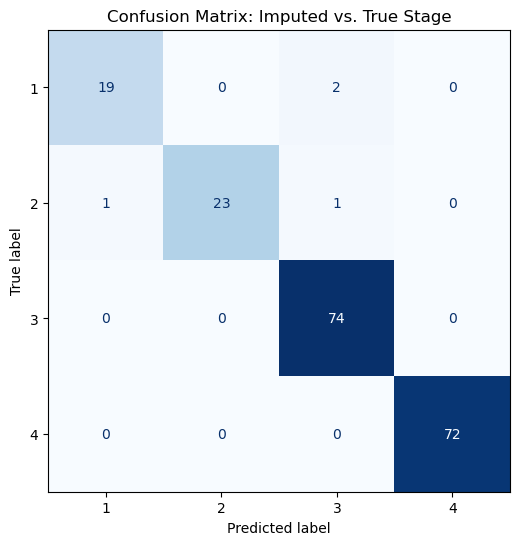

In [283]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true = true.values
y_pred = stage_impA[held_out_index]

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[1,2,3,4])

# Display it
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[1,2,3,4]
)
fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title("Confusion Matrix: Imputed vs. True Stage")
plt.show()


In [284]:
X_imp = pd.concat([df[predictors], df[['COMBINED_STAGE_GROUP']]], axis=1)
X_imp = pd.get_dummies(X_imp)

imp = IterativeImputer(
    random_state=321,
    sample_posterior=False,
    max_iter=10,
    initial_strategy='most_frequent',
    verbose=2,
    tol=1e-6,
)

X_completed = imp.fit_transform(X_imp)
X_completed = pd.DataFrame(
    X_completed,
    index=X_imp.index,
    columns=X_imp.columns
)

stage_imp = np.rint(X_completed['COMBINED_STAGE_GROUP']).astype(int)
stage_imp = np.clip(stage_imp, 1, 4)

[IterativeImputer] Completing matrix with shape (2030, 27)
[IterativeImputer] Ending imputation round 1/10, elapsed time 0.10
[IterativeImputer] Change: 1.3543646759258876, scaled tolerance: 4e-06 
[IterativeImputer] Ending imputation round 2/10, elapsed time 0.22
[IterativeImputer] Change: 0.0, scaled tolerance: 4e-06 
[IterativeImputer] Early stopping criterion reached.


In [ ]:
df['COMBINED_STAGE_GROUP'] = stage_imp

In [286]:
df.to_csv('analysis_ready_mice_pred.csv', index=False)